# Contrasts: one structure, several measurements

Neutron reflectometry often measures one sample several times, changing only the scattering length density (SLD) of part of it: the water it sits in (D2O, H2O, a contrast-matched mixture) or the deuteration of a molecule.
Each measurement is a *contrast*. Fitted jointly, the contrasts pin down a structure that no single one of them determines.

Every contrast is an ordinary `Model`, with its own scale, background and resolution. What the contrasts have in common is shared in one of two ways:

- **by identity**: an assembly or material is one object used by several models, so it has one set of parameters;
- **by equality**: a parameter of one model follows the corresponding parameter of another (an equality constraint), where the objects must differ, e.g. a layer whose solvent differs between contrasts.

A `Project` offers two routes to that state:

| | when | API |
|---|---|---|
| **Add a contrast** | the contrast does not exist yet: derive it from a reference model | `Project.add_contrast` with `ReplaceMaterial` / `ReplaceFormula` |
| **Link contrasts** | the models exist already, built separately: tie their corresponding parameters | `Project.plan_link`, `Project.apply_link`, `Project.unlink` |

This tutorial does both on simulated data of a film on silicon, measured in D2O, H2O and silicon-matched water (CMSi). The [multiple contrasts tutorial](multi_contrast.ipynb) fits real data of a surfactant monolayer with the assembly-level `constrain_multiple_contrast`.

First configure matplotlib to place figures in the notebook and import the needed modules.

In [1]:
%matplotlib inline

In [2]:
import json

import matplotlib.pyplot as plt
import numpy as np
import scipp as sc
from easyscience import global_object

from easyreflectometry import Project
from easyreflectometry.contrasts import LayoutMismatch
from easyreflectometry.contrasts import ReplaceMaterial
from easyreflectometry.fitting import MultiFitter
from easyreflectometry.model import Model
from easyreflectometry.model import ModelCollection
from easyreflectometry.sample import Layer
from easyreflectometry.sample import Material
from easyreflectometry.sample import Multilayer
from easyreflectometry.sample import Sample

## The reference contrast

The beam enters through the silicon block, crosses its native oxide and an 80 Å film, and is reflected from the water below:

| layer | material | SLD (10⁻⁶ Å⁻²) | thickness (Å) | roughness (Å) |
|---|---|---|---|---|
| superphase | Si | 2.07 | ∞ | |
| oxide | SiO2 | 3.47 | 15 | 3 |
| film | Film | 2.0 | 80 | 5 |
| subphase | D2O | 6.36 | ∞ | 4 |

In [3]:
si = Material(sld=2.07, isld=0.0, name='Si')
sio2 = Material(sld=3.47, isld=0.0, name='SiO2')
film = Material(sld=2.0, isld=0.0, name='Film')
d2o = Material(sld=6.36, isld=0.0, name='D2O')

oxide_layer = Layer(material=sio2, thickness=15.0, roughness=3.0, name='SiO2')
film_layer = Layer(material=film, thickness=80.0, roughness=5.0, name='Film')
d2o_layer = Layer(material=d2o, thickness=0.0, roughness=4.0, name='D2O')

reference = Model(
    sample=Sample(
        Multilayer(Layer(material=si, thickness=0.0, roughness=0.0, name='Si'), name='Superphase'),
        Multilayer([oxide_layer, film_layer], name='Oxide and film'),
        Multilayer(d2o_layer, name='Subphase'),
    ),
    background=2e-7,
    name='Film in D2O',
)

project = Project()
project.models = ModelCollection(reference)

## Adding contrasts

`add_contrast` builds a new model from a reference and a list of substitutions, and adds it to the project.
`ReplaceMaterial(old, new)` uses `new` wherever the reference uses `old`; `ReplaceFormula(target, formula)` gives a layer or density material another chemical formula (isotopic substitution).
The reference is not changed, and the new model's scale, background and resolution start as copies of the reference's but are its own.

In [4]:
h2o = Material(sld=-0.56, isld=0.0, name='H2O')
cmsi = Material(sld=2.07, isld=0.0, name='CMSi')

h2o_index = project.add_contrast(0, 'Film in H2O', [ReplaceMaterial(d2o, h2o)])
cmsi_index = project.add_contrast(0, 'Film in CMSi', [ReplaceMaterial(d2o, cmsi)])

for model in project.models:
    print(f'{model.name:13s}', ' | '.join(layer.material.name for assembly in model.sample for layer in assembly.layers))

Film in D2O   Si | SiO2 | Film | D2O
Film in H2O   Si | SiO2 | Film | H2O
Film in CMSi  Si | SiO2 | Film | CMSi


An assembly the substitutions do not touch is **shared**: the oxide and film are one object in all three models, so they have one thickness, one roughness and one SLD.
`parameter_models` tells which models a parameter belongs to:

In [5]:
h2o_model, cmsi_model = project.models[h2o_index], project.models[cmsi_index]

print('oxide and film shared:', h2o_model.sample[1] is reference.sample[1] and cmsi_model.sample[1] is reference.sample[1])
print('film thickness belongs to models', project.parameter_models(film_layer.thickness))

film_layer.thickness.value = 82.0
print('film thickness in H2O:', h2o_model.sample[1].layers[1].thickness.value)
print('film thickness in CMSi:', cmsi_model.sample[1].layers[1].thickness.value)
film_layer.thickness.value = 80.0

oxide and film shared: True
film thickness belongs to models [0, 1, 2]
film thickness in H2O: 82.0
film thickness in CMSi: 82.0


An assembly a substitution touches is **copied**, and every parameter of the copy follows the reference's, except those of the replacement.
So each contrast has its own subphase, in its own water, whose roughness follows the D2O one:

In [6]:
h2o_roughness = h2o_model.sample[2].layers[0].roughness
print('H2O subphase roughness independent:', h2o_roughness.independent)

d2o_layer.roughness.value = 4.5
print('D2O roughness 4.5 Å -> H2O roughness', h2o_roughness.value, 'Å')
d2o_layer.roughness.value = 4.0

print('scale is per contrast:', h2o_model.scale is not reference.scale)

H2O subphase roughness independent: False
D2O roughness 4.5 Å -> H2O roughness 4.5 Å
scale is per contrast: True


## Simulated measurements

We simulate the three measurements from the structure above, each with its own scale and background, and 5 % noise.

In [7]:
q = np.linspace(0.01, 0.25, 200)
truth = {'oxide thickness': 15.0, 'film thickness': 80.0, 'film SLD': 2.0, 'film roughness': 5.0}
scales = [1.0, 0.95, 1.0]
backgrounds = [2e-7, 5e-6, 1e-6]
rng = np.random.default_rng(7)

data = sc.DataGroup({'coords': {}, 'data': {}})
for index, model in enumerate(project.models):
    model.scale.value, model.background.value = scales[index], backgrounds[index]
    r_true = model.interface.fit_func(q, model.unique_name)
    data['coords'][f'Qz_{index}'] = sc.array(dims=[f'Qz_{index}'], values=q, unit='1/angstrom')
    data['data'][f'R_{index}'] = sc.array(
        dims=[f'Qz_{index}'], values=r_true * rng.normal(1.0, 0.05, q.size), variances=(0.05 * r_true) ** 2
    )

## A joint fit

We start from a wrong guess, keep the backgrounds at their known values, and fit the oxide thickness, the film's thickness, SLD and roughness, and each contrast's scale.
The structural parameters are free once, in the reference; the contrasts share or follow them.

In [8]:
oxide_layer.thickness.value = 25.0
film_layer.thickness.value = 70.0
film.sld.value = 1.0
film_layer.roughness.value = 3.0

for model in project.models:
    for parameter in model.get_fit_parameters():
        parameter.fixed = True
    model.scale.fixed = False
    model.scale.min, model.scale.max = 0.5, 1.5

for parameter, (low, high) in (
    (oxide_layer.thickness, (5.0, 40.0)),
    (film_layer.thickness, (50.0, 110.0)),
    (film.sld, (0.0, 4.0)),
    (film_layer.roughness, (1.0, 10.0)),
):
    parameter.min, parameter.max = low, high
    parameter.fixed = False

fitter = MultiFitter(*project.models)
analysed = fitter.fit(data)

fitted = {
    'oxide thickness': oxide_layer.thickness.value,
    'film thickness': film_layer.thickness.value,
    'film SLD': film.sld.value,
    'film roughness': film_layer.roughness.value,
}
for name, value in fitted.items():
    print(f'{name:16s} truth {truth[name]:6.2f}   fit {value:6.2f}')
print('scales:', [round(float(model.scale.value), 3) for model in project.models])

CollectionBase is deprecated and will be removed in a future version. Please migrate to ModelBase or EasyList.


oxide thickness  truth  15.00   fit  15.11
film thickness   truth  80.00   fit  79.98
film SLD         truth   2.00   fit   2.00
film roughness   truth   5.00   fit   5.05
scales: [0.993, 0.938, 0.977]


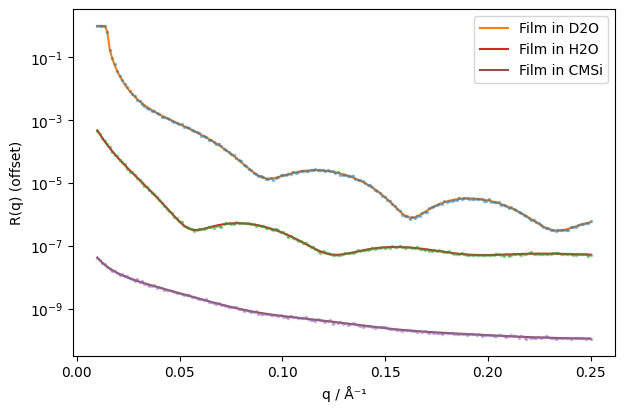

In [9]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for index, model in enumerate(project.models):
    offset = 10.0 ** (-2 * index)
    measured = data['data'][f'R_{index}']
    ax.errorbar(q, measured.values * offset, yerr=np.sqrt(measured.variances) * offset, fmt='.', ms=3, alpha=0.4)
    ax.plot(q, analysed[f'R_{index}_model'].values * offset, lw=1.5, label=model.name)
ax.set_yscale('log')
ax.set_xlabel('q / Å⁻¹')
ax.set_ylabel('R(q) (offset)')
ax.legend()

## Linking contrasts that were built separately

Sometimes the models exist already: built by hand, loaded from separate files, or kept from an older project.
Linking ties one model's parameters (the *follower*) to the corresponding parameters of another (the *reference*).

Here a fourth measurement, in water contrast-matched to SLD 4 (4MW), gets a model built from scratch.
It uses the same Si, SiO2 and Film materials, as a model built from a project's materials would, but its own layers, its own water and a poor starting guess.

In [10]:
water_4mw = Material(sld=4.0, isld=0.0, name='4MW')
separate = Model(
    sample=Sample(
        Multilayer(Layer(material=si, thickness=0.0, roughness=0.0, name='Si'), name='Superphase'),
        Multilayer(
            [
                Layer(material=sio2, thickness=10.0, roughness=2.0, name='SiO2'),
                Layer(material=film, thickness=60.0, roughness=2.0, name='Film'),
            ],
            name='Oxide and film',
        ),
        Multilayer(Layer(material=water_4mw, thickness=0.0, roughness=3.0, name='4MW'), name='Subphase'),
    ),
    name='Film in 4MW',
    interface=project.models.interface,
)
project.models.add_model(separate)
separate_index = len(project.models) - 1

`plan_link` lays out what linking would do, without changing anything.
Parameters correspond by their position in the model, so both models need the same layout: the same assemblies and layers, with materials of the same kind.
Each row of the plan says what happens to one pair of corresponding parameters:

In [11]:
plan = project.plan_link(separate_index, 0)

for row in plan.rows:
    print(f'{row.path:40s} {row.action:10s} {row.reason}')

scale                                    skip       per contrast
background                               skip       per contrast
sample/0/layers/0/material/isld          skip       shared object
sample/0/layers/0/material/sld           skip       shared object
sample/0/layers/0/roughness              skip       not used
sample/0/layers/0/thickness              skip       not used
sample/1/layers/0/material/isld          skip       shared object
sample/1/layers/0/material/sld           skip       shared object
sample/1/layers/0/roughness              tie        
sample/1/layers/0/thickness              tie        
sample/1/layers/1/material/isld          skip       shared object
sample/1/layers/1/material/sld           skip       shared object
sample/1/layers/1/roughness              tie        
sample/1/layers/1/thickness              tie        
sample/2/layers/0/material/isld          undecided  material chemistry
sample/2/layers/0/material/sld           undecided  material chemistr

- **scale** and **background** stay per contrast;
- the shared materials' SLDs are already one parameter (`shared object`), and the media's thicknesses and the superphase roughness do not enter the calculation (`not used`);
- the structural parameters will be tied (`tie`);
- the 4MW SLD is **undecided**: contrasts usually differ in their materials' chemistry (SLD, density, scattering lengths), so linking never ties it without being told to.

A plan with undecided rows cannot be applied:

In [12]:
try:
    project.apply_link(plan)
except ValueError as error:
    print(error)

Decide whether to tie sample/2/layers/0/material/isld, sample/2/layers/0/material/sld before linking.


`materials='skip'` keeps every material's chemistry per model; `materials='tie'` would tie it too, which here would give the 4MW water the D2O SLD.
`apply_link` ties all the rows marked `tie` or none of them, and returns a record of what it did:

In [13]:
plan = project.plan_link(separate_index, 0, materials='skip')
record = project.apply_link(plan)

separate_film = separate.sample[1].layers[1]
print(f'{len(record.pairs)} parameters tied')
print(f'4MW film thickness: {separate_film.thickness.value:.2f} Å')
print('follows the reference:', not separate_film.thickness.independent)
print('4MW water SLD:', water_4mw.sld.value)

5 parameters tied
4MW film thickness: 79.98 Å
follows the reference: True
4MW water SLD: 4.0


`unlink` removes the ties of one record together.
A tie replaces the follower's value and bounds, so by default they are restored from before the link; `restore_state=False` keeps the current ones instead.

In [14]:
project.unlink(record)
print(f'after unlink, 4MW film thickness: {separate_film.thickness.value:.2f} Å')
print('independent:', separate_film.thickness.independent)

after unlink, 4MW film thickness: 60.00 Å
independent: True


Models whose layouts do not correspond are refused as a whole rather than tied partially:

In [15]:
separate.sample[1].add_layer(Layer(material=film, thickness=5.0, roughness=1.0, name='Extra'))
try:
    project.plan_link(separate_index, 0)
except LayoutMismatch as error:
    print(error)
separate.sample[1].remove_layer(2)

'Film in 4MW' and 'Film in D2O' differ in layout at sample/1/layers/2/material/isld.


We link the 4MW model again, to keep it with the project.

In [16]:
record = project.apply_link(project.plan_link(separate_index, 0, materials='skip'))

## Detaching a shared parameter

A parameter the contrasts share can be freed in one of them, e.g. when the film swells in one water.
`detach` gives that model its own copy of the assembly, with every other parameter still tied to the shared one:

In [17]:
project.detach(film_layer.thickness, model_index=cmsi_index)

cmsi_film = cmsi_model.sample[1].layers[1]
print('film thickness now belongs to models', project.parameter_models(film_layer.thickness))
print('CMSi film thickness independent:', cmsi_film.thickness.independent)
print('CMSi film roughness follows the reference:', not cmsi_film.roughness.independent)

film thickness now belongs to models [0, 1]
CMSi film thickness independent: True
CMSi film roughness follows the reference: True


## Save / load

The project file keeps which model each contrast was derived from, the links, and the sharing between models.

In [18]:
project_dict = json.loads(json.dumps(project.as_dict()))

global_object.map._clear()  # simulate a fresh Python session
reloaded = Project()
reloaded.from_dict(project_dict)

print('derived from:', [reloaded.contrast_reference(index) for index in range(len(reloaded.models))])
print('links:', [(link.follower.name, link.reference.name, len(link.pairs)) for link in reloaded.links])
print('H2O shares the oxide and film:', reloaded.models[1].sample[1] is reloaded.models[0].sample[1])

CollectionBase is deprecated and will be removed in a future version. Please migrate to ModelBase or EasyList.


derived from: [None, 0, 0, None]
links: [('Film in 4MW', 'Film in D2O', 5)]
H2O shares the oxide and film: True


## Summary

| task | API |
|---|---|
| derive a contrast from a reference model | `Project.add_contrast(reference_index, name, [ReplaceMaterial(old, new), ReplaceFormula(target, formula)])` |
| which models a parameter belongs to | `Project.parameter_models(parameter)` |
| the model a contrast was derived from | `Project.contrast_reference(model_index)` |
| link two existing models | `Project.plan_link(follower, reference, materials=None / 'skip' / 'tie')`, then `Project.apply_link(plan)` |
| undo a link | `Project.unlink(record, restore_state=True)`; all links: `Project.links` |
| free a shared parameter in one model | `Project.detach(parameter, model_index)` |

In both routes scale, background and resolution stay per contrast, and the result is saved with the project.
The application offers the same operations as **Add contrast of the selected model…** and **Link contrasts** on its Sample page.